**Wojciech Olejnik**

# Sieci neuronowe wielowarstwowe

Celem ćwiczenia jest badanie działania sieci neuronowych w zastosowaniu do zadania klasyfkacji.Do badań wykorzysatno klasę **_MLPClassifier_** z pakietu **_sklearn_**

# Przygotowanie danych do badań

In [59]:
import matplotlib.pyplot as plt
from datasets import make_checkerboard, make_spiral
from sklearn.datasets import make_circles
from sklearn.neural_network import MLPClassifier
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

**Szachownica**

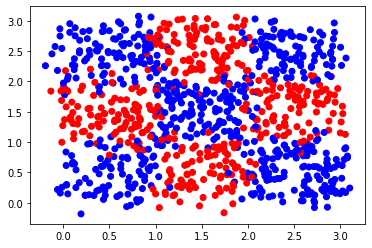

In [27]:
x, y = make_checkerboard(1000,3, noise=.1)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

**Półksiężyce**

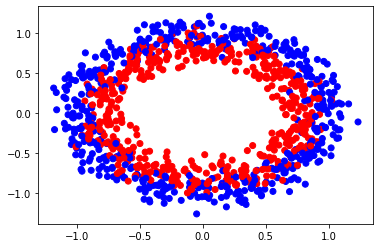

In [31]:
x, y = make_circles(1000, noise=0.1)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

**Zagnieżdżone spirale**

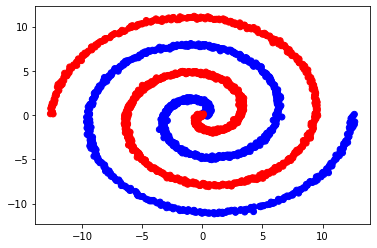

In [30]:
x, y = make_spiral(1000, noise=.1)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

# Tworzenie modelu

Przygotowanie danych

In [63]:
# https://www.python-course.eu/neural_networks_with_scikit.php
X, y = make_circles(1000, noise=0.1)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=10)

Tworzenie modelu 

In [36]:
h=2
K=10
alpha=1e-54
hidden_layer_sizes = [K] * h
clf = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, solver="adam" alpha=alpha)

In [37]:
clf.fit(X_train, y_train)

MLPClassifier(alpha=1e-54, hidden_layer_sizes=[10, 10])

In [43]:
y_true = y_test
y_pred = clf.predict(X_test)

acc = accuracy_score(y_true, y_pred)
print(f'acc => {acc}')

f1 = f1_score(y_true, y_pred)
print(f'f1 => {f1}')

y_score = clf.predict_proba(X_test)
auc = roc_auc_score(y_true, y_score[:, 1])
print(f'accuracy => {auc}')

acc_train = accuracy_score(y_train, clf.predict(X_train))
print(f'accuracy_train => {acc_train}')

acc => 0.796
f1 => 0.801556420233463
accuracy => 0.8572275641025642
accuracy_train => 0.818


In [56]:
t1_fit = time.time()
clf.fit(
    X_train, y_train
)  # this is done two times. But this separation might be better for testing.
t_fit = time.time() - t1_fit

t1_pred = time.time()
clf.predict(X_test)
t_pred = time.time() - t1_pred
print(f"Czas uczenia: {t_fit}")
print(f"Czas predykcji: {t_pred}")
n_params = sum([a.size for a in clf.coefs_]) + sum([a.size for a in clf.intercepts_])
print(f"Liczba parametrow sieci: {n_params}")

Czas uczenia: 0.2913651466369629
Czas predykcji: 0.0003161430358886719
Liczba parametrow sieci: 151


Wizualizacji granic decyzji

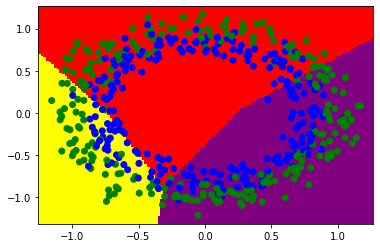

In [72]:
# Plot decision
plt.figure()

# Decision boundary
x_min, x_max = X_test[:, 0].min() - 0.1, X_test[:, 0].max() + 0.1
y_min, y_max = X_test[:, 1].min() - 0.1, X_test[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

cmap_light = ListedColormap(["red", "purple", "yellow"])
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

# Plot class
colors = ["green" if item == 0 else "blue" for item in y_test]
plt.scatter(X_test[:, 0], X_test[:, 1], c=colors)
plt.show()

Wizualizacja sieci dwuwarstwowej. Aby cztelnie przedstawić tablice decyzyjne oraz separacje danych, za pomoca prostych przygotowano następujacy zestaw danych

In [73]:
X_2, y_2 = datasets.make_blobs(n_samples=1000, centers=3, random_state=8)
clf_2 = MLPClassifier(hidden_layer_sizes=2)

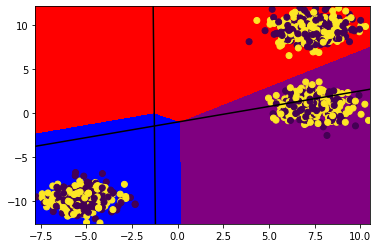

In [90]:
clf.fit(X_2, y_2)

# Plot
plt.figure()

x_min, x_max = X_2[:, 0].min() - 0.1, X_2[:, 0].max() + 0.1
y_min, y_max = X_2[:, 1].min() - 0.1, X_2[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

cmap_light = ListedColormap(["red", "purple", "blue"])
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)


plt.scatter(X_2[:, 0], X_2[:, 1], c=y)
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
for i in range(len(clf.intercepts_[0])):
    w = clf.coefs_[0][:, i]
    a = -w[0] / w[1]
    xx = np.linspace(xmin, xmax)
    yy = a * xx - (clf.intercepts_[0][i]) / w[1]

    # Plot the hyperplane
    plt.plot(xx, yy, "k-")

plt.ylim(ymin, ymax)
plt.show()

# Część eksperymentalna